## 23. Program - 4 - Analysis of Beams SFD and BMD - Part-2

23. Program - 4 - Analysis of Beams SFD and BMD - Part-2

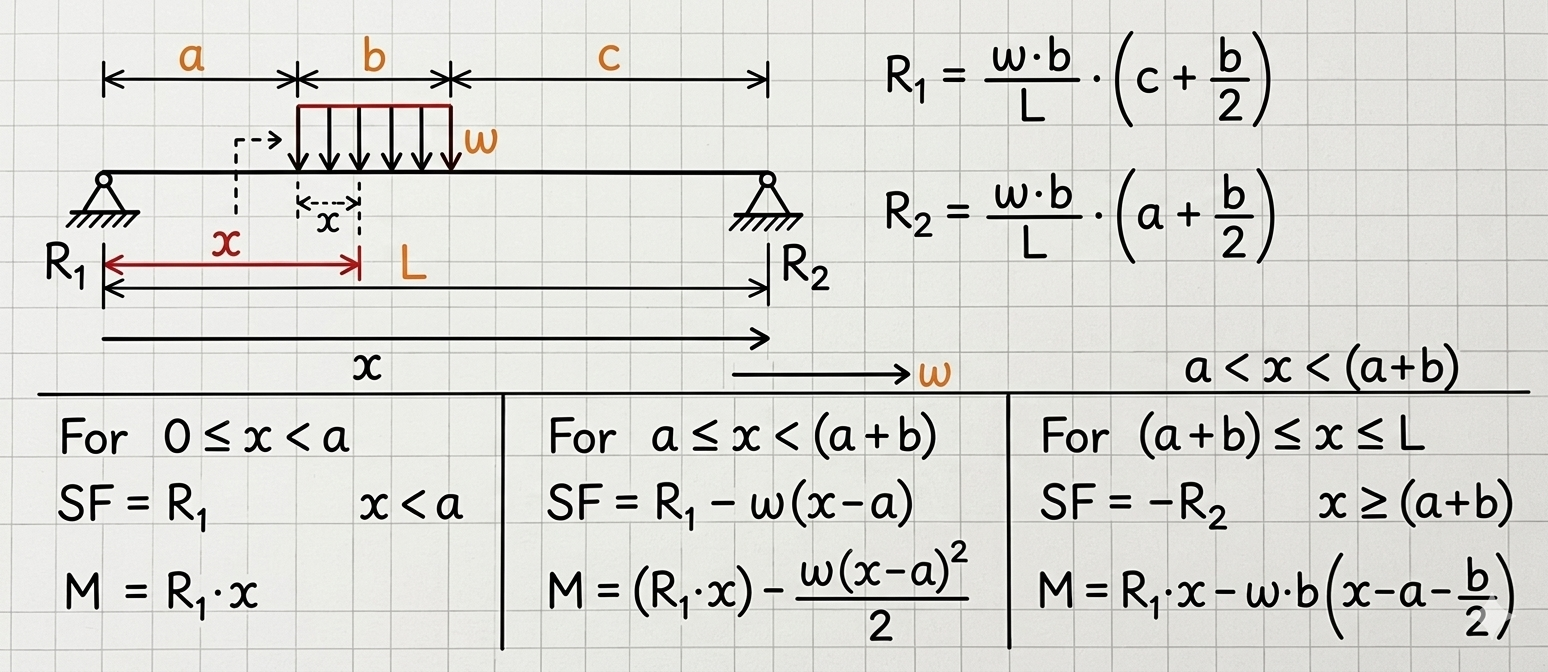

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

W = 50 # udl N/m
L = 10 # Length of the beam

a = 2.5
b = 5
c = L - (a+b)  # 2.5

R1 = (W*b/L)*(c + b/2)
R2 = (W*b/L)*(a + b/2)

R1 # half load to check

125.0

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

W = 50 # udl N/m
L = 10 # Length of the beam

a = 3
b = 5
c = L - (a+b)  # 2.0

R1 = (W*b/L)*(c + b/2)
R2 = (W*b/L)*(a + b/2)

R1

112.5

[np.float64(0.0), np.float64(0.05025125628140704), np.float64(0.10050251256281408), np.float64(0.15075376884422112), np.float64(0.20100502512562815), np.float64(0.2512562814070352), np.float64(0.30150753768844224), np.float64(0.35175879396984927), np.float64(0.4020100502512563), np.float64(0.45226130653266333), np.float64(0.5025125628140704), np.float64(0.5527638190954774), np.float64(0.6030150753768845), np.float64(0.6532663316582915), np.float64(0.7035175879396985), np.float64(0.7537688442211056), np.float64(0.8040201005025126), np.float64(0.8542713567839196), np.float64(0.9045226130653267), np.float64(0.9547738693467337), np.float64(1.0050251256281408), np.float64(1.0552763819095479), np.float64(1.105527638190955), np.float64(1.155778894472362), np.float64(1.206030150753769), np.float64(1.256281407035176), np.float64(1.306532663316583), np.float64(1.35678391959799), np.float64(1.407035175879397), np.float64(1.4572864321608041), np.float64(1.5075376884422111), np.float64(1.5577889447

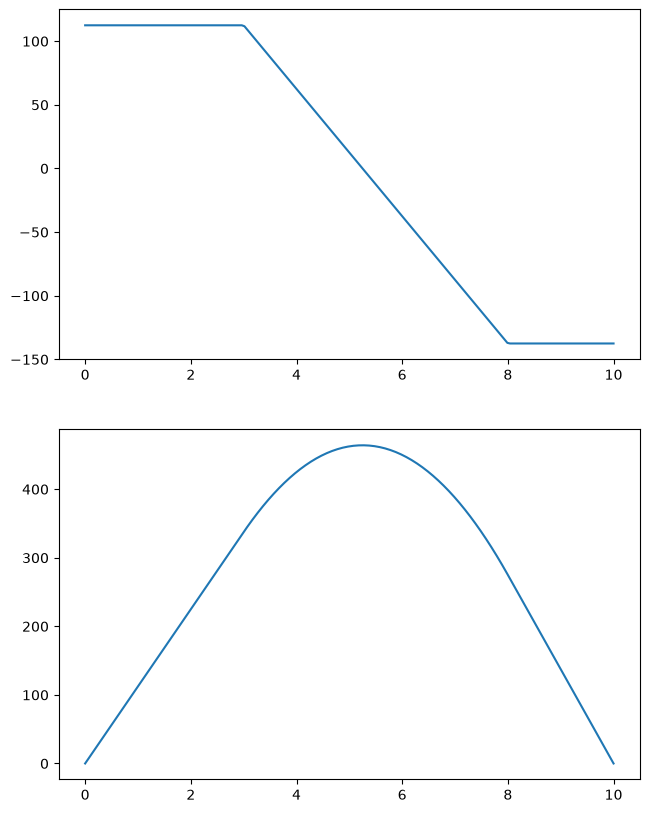

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

W = 50 # udl N/m
L = 10 # Length of the beam

a = 3
b = 5
c = L - (a+b)  # 2.0

R1 = (W*b/L)*(c + b/2)
R2 = (W*b/L)*(a + b/2)

#print(R1)

l = np.linspace(0,L,200)

#print(l)

X = []
SF = []
M = []

for x in l:
    if x<a:
            sf = R1
            m  = R1*x
            #print(sf)
    elif a<x<(a+b):
            sf = R1-W*(x-a)
            m  = (R1*x) -W*(x-a)**2/2
            #print(sf)
    elif x>(a+b):
            sf = -R2
            m  = R2*(L-x)
            #print(sf)
    
    X.append(x)
    SF.append(sf)
    M.append(m)

#print(X)

plt.figure(figsize=(7.5,10))

plt.subplot(2,1,1)
plt.plot(X,SF)

plt.subplot(2,1,2)
plt.plot(X,M)

plt.show()

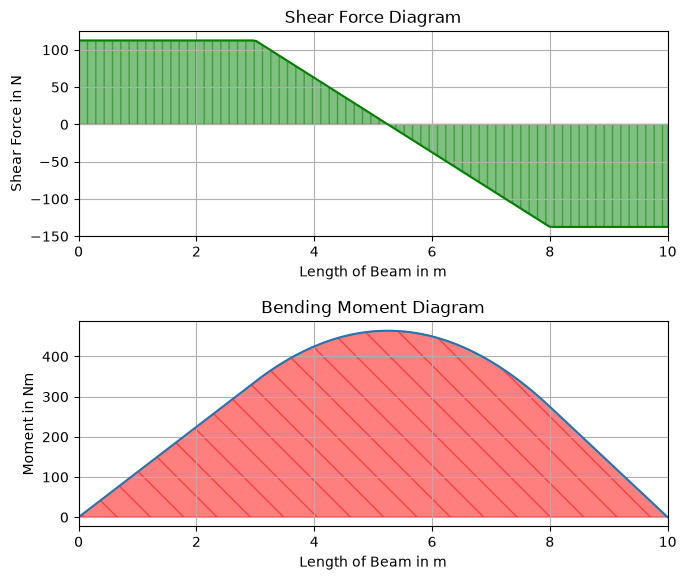

In [26]:
import numpy as np
import matplotlib.pyplot as plt

W = 50 # udl N/m
L = 10 # Length of the beam

a = 3
b = 5
c = L - (a+b)  # 2.0

R1 = (W*b/L)*(c + b/2)
R2 = (W*b/L)*(a + b/2)

#print(R1)

l = np.linspace(0,L,200)

#print(l)

X = []
SF = []
M = []

for x in l:
    if x<a:
            sf = R1
            m  = R1*x
            #print(sf)
    elif a<x<(a+b):
            sf = R1-W*(x-a)
            m  = (R1*x) -W*(x-a)**2/2
            #print(sf)
    elif x>(a+b):
            sf = -R2
            m  = R2*(L-x)
            #print(sf)
    
    X.append(x)
    SF.append(sf)
    M.append(m)

#print(X)

plt.figure(figsize=(7.5,6))

plt.subplot(2,1,1)
plt.plot(X,SF,color='green')
plt.fill_between(X,SF,color="green",hatch="||", alpha=0.5)
plt.title("Shear Force Diagram")
plt.xlabel("Length of Beam in m")
plt.ylabel("Shear Force in N")
plt.xlim(0,L)
plt.grid()

plt.tight_layout(pad=3.0)
plt.subplot(2,1,2)
plt.plot(X,M)
plt.fill_between(X,M,color='red',hatch="\\",alpha=0.5)
plt.title("Bending Moment Diagram")
plt.xlabel("Length of Beam in m")
plt.ylabel("Moment in Nm")
plt.xlim(0,L)
plt.grid()

plt.show()

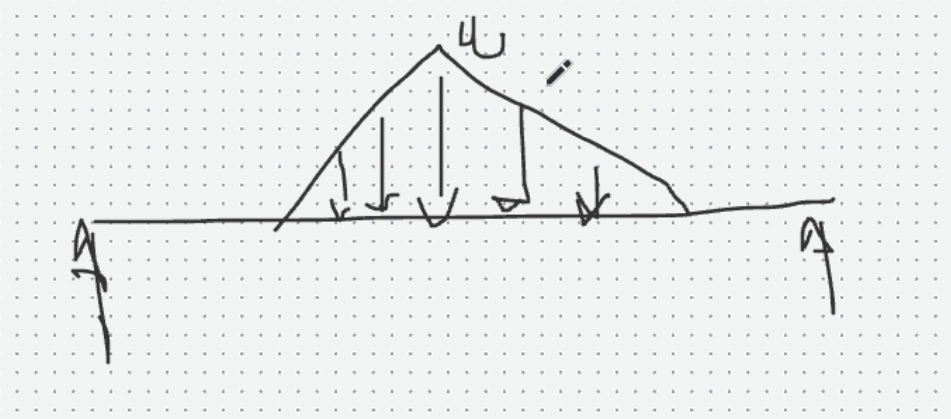

--- STRUCTURAL METRICS ---
Left Support Reaction (R1) : 58.333 N
Right Support Reaction (R2): 66.667 N
Zero Shear Location (x)    : 5.172 m
Max Bending Moment         : 259.041 Nm



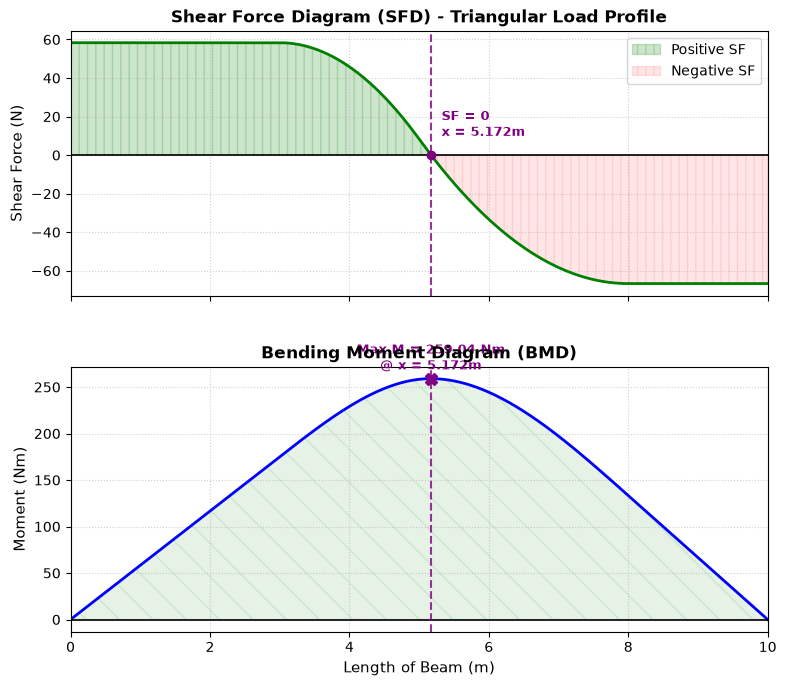

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETERS & INPUT SYSTEM
# ==========================================
W = 50.0  # Peak load intensity (N/m)
L = 10.0  # Total length of the beam (m)

# Segment breakdown based on the hand sketch
a = 3.0       # Distance before the load starts
b1 = 2.0      # Distance where load rises to peak W
b2 = 3.0      # Distance where load falls from peak W to 0
c = L - (a + b1 + b2)  # Distance after the load (2.0 m)

# ==========================================
# 2. CALCULATE SUPPORT REACTIONS (EXACT)
# ==========================================
# Rising triangle profile segment load and centroid
F1 = 0.5 * b1 * W
x1 = a + (2.0 / 3.0) * b1

# Falling triangle profile segment load and centroid
F2 = 0.5 * b2 * W
x2 = a + b1 + (1.0 / 3.0) * b2

# Static equilibrium matrix calculations
R2 = (F1 * x1 + F2 * x2) / L
R1 = (F1 + F2) - R2

# ==========================================
# 3. ANALYTICAL SOLUTION FOR MAX POSITION
# ==========================================
# Since R1 = 60.625 N and F1 = 50.0 N, zero shear drops inside the falling triangle (Region 3)
# Rearranging the integrated load profile equation to standard quadratic form: A*dx^2 + B*dx + C = 0
A = 0.5 * (W / b2)
B = -W
C = R1 - F1

# Solve for the exact localized zero-crossing root
dx_zero = (-B - np.sqrt(B**2 - 4 * A * C)) / (2 * A)
x_zero = a + b1 + dx_zero

# Maximum Bending Moment value equation calculation at critical coordinate point
w_x_zero = W - (W / b2) * dx_zero
f_rect = w_x_zero * dx_zero
f_tri = 0.5 * (W - w_x_zero) * dx_zero
max_bm = R1 * x_zero - F1 * (x_zero - x1) - f_rect * (dx_zero / 2.0) - f_tri * ((2.0 / 3.0) * dx_zero)

# Print structural telemetry results to console terminal output
print(f"--- STRUCTURAL METRICS ---")
print(f"Left Support Reaction (R1) : {R1:.3f} N")
print(f"Right Support Reaction (R2): {R2:.3f} N")
print(f"Zero Shear Location (x)    : {x_zero:.3f} m")
print(f"Max Bending Moment         : {max_bm:.3f} Nm\n")

# ==========================================
# 4. PIECEWISE ARRAYS COMPUTATION LOOP
# ==========================================
l = np.linspace(0, L, 1000)
X, SF, M = [], [], []

for x in l:
    if x < a:
        # Region 1: Prior to distribution block
        sf = R1
        m = R1 * x
    elif a <= x < (a + b1):
        # Region 2: Under the rising load profile curve
        dx = x - a
        w_x = (W / b1) * dx
        load_under = 0.5 * dx * w_x
        sf = R1 - load_under
        m = R1 * x - load_under * (dx / 3.0)
    elif (a + b1) <= x < (a + b1 + b2):
        # Region 3: Under the falling load profile curve
        dx = x - (a + b1)
        w_x = W - (W / b2) * dx
        load_under = F1 + 0.5 * (W + w_x) * dx
        f_r = w_x * dx
        f_t = 0.5 * (W - w_x) * dx
        sf = R1 - load_under
        m = R1 * x - F1 * (x - x1) - f_r * (dx / 2.0) - f_t * ((2.0 / 3.0) * dx)
    else:
        # Region 4: Beyond the distribution block
        sf = -R2
        m = R2 * (L - x)

    X.append(x)
    SF.append(sf)
    M.append(m)

# Convert outputs to strict numpy numeric array collections
SF_arr = np.array(SF)
M_arr = np.array(M)

# ==========================================
# 5. DIAGRAM RENDERING SETUP
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.5, 7.5), sharex=True)

# --- Subplot 1: Shear Force Diagram ---
ax1.plot(X, SF, color='green', lw=2)
ax1.fill_between(X, SF, 0, where=(SF_arr >= 0), color="green", hatch="||", alpha=0.2, label="Positive SF")
ax1.fill_between(X, SF, 0, where=(SF_arr < 0), color="red", hatch="||", alpha=0.1, label="Negative SF")
ax1.axhline(0, color='black', lw=1.2)

# Graph annotations for zero-point crossings
ax1.axvline(x_zero, color='purple', linestyle='--', alpha=0.8, lw=1.5)
ax1.plot(x_zero, 0, 'o', color='purple', markersize=6)
ax1.text(x_zero + 0.15, 10, f'SF = 0\nx = {x_zero:.3f}m', color='purple', fontsize=9.5, fontweight='bold')

ax1.set_title("Shear Force Diagram (SFD) - Triangular Load Profile", fontsize=12, fontweight='bold')
ax1.set_ylabel("Shear Force (N)", fontsize=11)
ax1.set_xlim(0, L)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc="upper right")

# --- Subplot 2: Bending Moment Diagram ---
ax2.plot(X, M, color='blue', lw=2)
ax2.fill_between(X, M, 0, where=(M_arr >= 0), color='green', hatch="\\", alpha=0.1)
ax2.fill_between(X, M, 0, where=(M_arr < 0), color='red', hatch="\\", alpha=0.2)
ax2.axhline(0, color='black', lw=1.2)

# Graph annotations for absolute maximum apex point
ax2.axvline(x_zero, color='purple', linestyle='--', alpha=0.8, lw=1.5)
ax2.plot(x_zero, max_bm, 'X', color='purple', markersize=8)
ax2.text(x_zero, max_bm + 10, f'Max M = {max_bm:.2f} Nm\n@ x = {x_zero:.3f}m', 
         color='purple', ha='center', fontsize=9.5, fontweight='bold')

ax2.set_title("Bending Moment Diagram (BMD)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Length of Beam (m)", fontsize=11)
ax2.set_ylabel("Moment (Nm)", fontsize=11)
ax2.set_xlim(0, L)
ax2.grid(True, linestyle=':', alpha=0.6)

# Apply tight layout constraints to clear subplots bounding frames nicely
plt.tight_layout(pad=3.0)

# Render windows frame execution loop target
plt.show()
